## Students Grades project

In [3]:
# IMPORT REQUIRED LIBRARIES

import pandas as pd
import scipy.stats as stats
import numpy as np
import matplotlib.pyplot as plt

ModuleNotFoundError: No module named 'pandas'

In [ ]:
students = pd.read_csv(';students.csv')

In [45]:
students.head(15)
students.describe()

,stud.id,age,height,weight,nc.score,score1,score2,online.tutorial,graduated,salary
count,8239.000000,8239.000000,8239.000000,8239.000000,8239.000000,4892.000000,4892.000000,8239.000000,8239.000000,1753.000000
mean,548910.484525,22.541571,171.380750,72.998131,2.166481,68.164963,69.494685,0.386212,0.212769,42522.112364
std,253849.389811,6.065111,11.077529,8.635162,0.811548,14.051762,14.395251,0.486910,0.409290,10333.139906
min,110250.000000,18.000000,135.000000,51.400000,1.000000,30.000000,31.000000,0.000000,0.000000,11444.141653
25%,331222.500000,20.000000,163.000000,66.500000,1.460000,58.000000,59.000000,0.000000,0.000000,35206.541598
50%,545132.000000,21.000000,171.000000,71.800000,2.040000,70.000000,71.000000,0.000000,0.000000,41672.009748
75%,770807.500000,23.000000,180.000000,78.500000,2.780000,78.000000,80.000000,1.000000,0.000000,49372.540906
max,989901.000000,64.000000,206.000000,116.000000,4.000000,97.000000,98.000000,1.000000,1.000000,75596.793441


In [46]:
students.groupby(by='major').mean('nc.score')

,stud.id,age,height,weight,nc.score,score1,score2,online.tutorial,graduated,salary
major,,,,,,,,,,
Biology,545373.010019,22.545398,169.798998,71.854477,2.145304,77.101998,78.885384,0.390106,0.206637,47942.830314
Economics and Finance,545235.079305,22.494713,173.838369,74.711782,2.186737,66.439752,67.150311,0.388973,0.222810,49696.171910
Environmental Sciences,548685.338253,22.709717,172.097786,73.608180,2.164699,71.531250,73.166667,0.388069,0.212177,37652.678362
Mathematics and Statistics,549955.741224,22.376327,175.699592,76.082041,2.170139,88.095047,89.796519,0.395102,0.235102,48443.506902
Political Science,556864.715464,22.593814,168.573883,71.012371,2.134749,54.980700,56.083233,0.352577,0.198625,36390.273276
Social Sciences,546961.695652,22.451581,168.317194,70.702767,2.217460,44.331667,45.135000,0.411067,0.203557,32044.006106


In [47]:
students.groupby(['major']).size()

major
Biology                       1597
Economics and Finance         1324
Environmental Sciences        1626
Mathematics and Statistics    1225
Political Science             1455
Social Sciences               1012
dtype: int64

In [48]:
# Testing mean difference of nc.score between male and female
stats.ttest_ind(students['nc.score'][students['gender'] == 'Male'],
                students['nc.score'][students['gender'] == 'Female'])

Ttest_indResult(statistic=1.8432091452726262, pvalue=0.06533438488251721)

In [49]:
#So, what can we conclude about the differences in mean among the groups?

In [50]:
students.groupby(['gender'])['nc.score'].mean([])

gender
Female    2.149966
Male      2.182921
Name: nc.score, dtype: float64

In [51]:
std = pd.DataFrame(students.groupby(['gender'])['nc.score'].std())

In [52]:
students.groupby('gender')['nc.score'].count()

gender
Female    4110
Male      4129
Name: nc.score, dtype: int64

In [53]:
students.groupby('graduated')['nc.score'].count()

graduated
0    6486
1    1753
Name: nc.score, dtype: int64

In [54]:
std

,nc.score
gender,
Female,0.818226
Male,0.804608


In [55]:
# Hardcoded, no time to do it -- standard error females
0.818226/np.sqrt(4110)

0.012762988108927046

In [56]:
# Hardcoded, no time to do it -- standard error males
0.804608/np.sqrt(4129)

0.012521659932502793

In [57]:
# Testing mean difference of nc.score between male and female
stats.ttest_ind(students['salary'][students['gender'] == 'Male'],
                students['salary'][students['gender'] == 'Female'])

Ttest_indResult(statistic=nan, pvalue=nan)

In [58]:
#What is wrong here?

In [59]:
#....

In [60]:
#There are missing values (NaN, not a number) in the variable

In [61]:
#Let's try an example with normal distributions

In [62]:
sample1= pd.DataFrame(np.random.normal(30, 16, 50))
sample2= pd.DataFrame(np.random.normal(33, 18, 50))

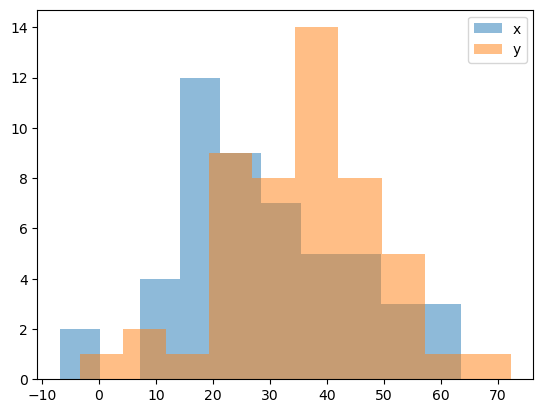

In [63]:
plt.hist(sample1, bins=10, alpha=0.5, label='x')
plt.hist(sample2, bins=10, alpha=0.5, label='y')
plt.legend(loc='upper right')
plt.show()

In [64]:
stats.ttest_ind(sample1,sample2)

Ttest_indResult(statistic=array([-2.0207995]), pvalue=array([0.04602853]))

In [65]:
sample1.describe()

,0
count,50.000000
mean,29.591762
std,15.670929
min,-6.824619
25%,18.951380
50%,27.085890
75%,39.737698
max,63.604082


In [66]:
a1 = sample1.std()/np.sqrt(sample1.count())
a1

0    2.216204
dtype: float64

In [67]:
# Only from illustrative purposes I select a random sample with mean the mean of sample 1 
#and standard deviation its standard error
# This is not how the ttest actually work but is to give you a visual hint of what is going on
sampleM1= pd.DataFrame(np.random.normal(sample1.mean(), a1, 50))
sampleM1.describe()

,0
count,50.000000
mean,29.779384
std,1.951228
min,25.474095
25%,28.340222
50%,30.037083
75%,31.200849
max,33.951261


In [68]:
sample2.describe()

,0
count,50.000000
mean,35.640250
std,14.225300
min,-3.399622
25%,26.980057
50%,36.345460
75%,45.063237
max,72.340357


In [69]:
a2 = sample2.std()/np.sqrt(sample2.count())
a2

0    2.011761
dtype: float64

In [70]:
# Only from illustrative purposes I select a random sample with mean the mean of sample 2
#and standard deviation its standard error
# This is not how the ttest actually work but is to give you a visual hint of what is going on
sampleM2= pd.DataFrame(np.random.normal(sample2.mean(), a2, 50))
sampleM2.describe()

,0
count,50.000000
mean,36.084710
std,1.999693
min,30.741938
25%,35.081705
50%,36.132665
75%,37.205865
max,40.726638


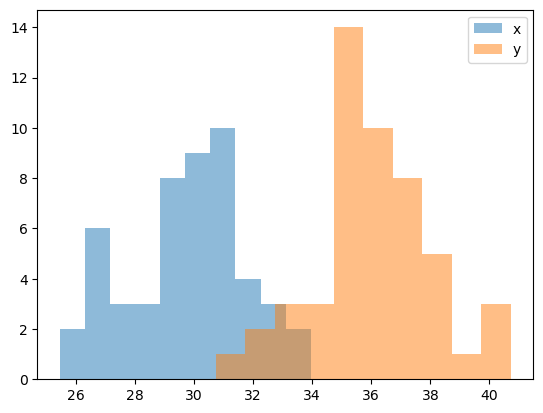

In [71]:
# Here I plot the histogram of the two normal distributions I have built for illustrative purposes
plt.hist(sampleM1, bins=10, alpha=0.5, label='x')
plt.hist(sampleM2, bins=10, alpha=0.5, label='y')
plt.legend(loc='upper right')
plt.show()

In [72]:
students.groupby(['gender'])['height'].describe()

,count,mean,std,min,25%,50%,75%,max
gender,,,,,,,,
Female,4110.0,163.653285,7.919726,135.0,158.0,164.0,169.0,193.0
Male,4129.0,179.072657,7.988852,144.0,174.0,179.0,184.0,206.0


In [73]:
import seaborn as sns

<Axes: xlabel='height', ylabel='Count'>

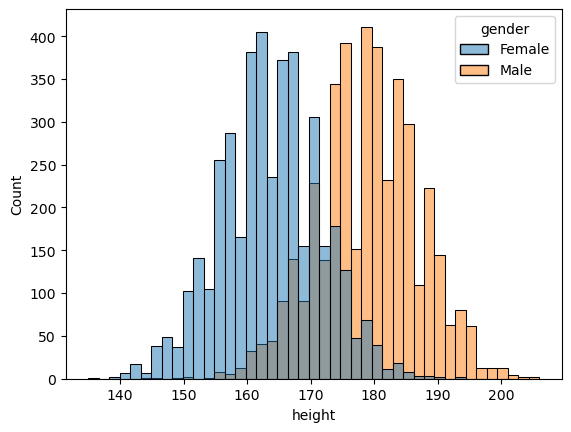

In [74]:
sns.histplot(x = 'height', hue = "gender", data = students)

In [75]:
stats.ttest_ind(students['height'][students['gender'] == 'Male'],
                students['height'][students['gender'] == 'Female'])

Ttest_indResult(statistic=87.97575064523302, pvalue=0.0)

In [76]:
tab2 = pd.crosstab(index=students['gender'], columns=students['major'])

In [77]:
tab2/tab2.sum()

major,Biology,Economics and Finance,Environmental Sciences,Mathematics and Statistics,Political Science,Social Sciences
gender,,,,,,
Female,0.600501,0.348187,0.45818,0.225306,0.672165,0.682806
Male,0.399499,0.651813,0.54182,0.774694,0.327835,0.317194
